In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import time
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import torch.nn as nn
import gc
import os

In [3]:
# select device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: cuda


In [4]:
# for getting the data into colab runtime
!cp /content/drive/MyDrive/gervigreing_lokaverk/NWPU-RESISC45.zip /content/
!unzip -q /content/NWPU-RESISC45.zip -d /content/data

In [7]:
batch_size = 128

# Image transformations
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    #transforms.RandomHorizontalFlip(),
    transforms.GaussianBlur(kernel_size=3, sigma=0.5),
    transforms.RandomRotation(degrees=90),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# Load dataset (without transforms)
if device.type == 'cuda':
    full_dataset = datasets.ImageFolder(
        #root="/content/data/NWPU-RESISC45",
        root="data/NWPU-RESISC45",
        transform=None
    )
    print('loaded from drive')
elif device.type == 'mps':
    full_dataset = datasets.ImageFolder(
    root="datageo/filter",
    transform=None
    )
    print('local data')
else:
    print('error')

print(len(full_dataset))

# Split train, val, test
train_data, val_data, test_data = random_split(
    full_dataset,
    #[11200, 560, 2240], # 80%, 4%, 16% / 20 outputs
    [25200, 1260, 5040], # 80%, 4%, 16% / 45 outputs
    generator=torch.Generator().manual_seed(42)
)

loaded from drive
31500


In [8]:
# only apply augmentations to training set
# create datasets
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

        # Decode the original images once, before DataLoader workers start.
        print(f"Caching {len(dataset):,} images in CPU RAM...")
        self.cached_samples = [dataset[i] for i in range(len(dataset))]
        print("Cache ready.")

    def __getitem__(self, index):
        image, target = self.cached_samples[index]
        image = image.copy()

        # Apply random augmentations afresh each time this image is requested.
        if self.transform is not None:
            image = self.transform(image)

        return image, target

    def __len__(self):
        return len(self.cached_samples)


train_dataset = CustomDataset(train_data, transform=train_transforms)
val_dataset = CustomDataset(val_data, transform=test_transforms)
test_dataset = CustomDataset(test_data, transform=test_transforms)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True, num_workers=2, persistent_workers=True
)
val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False, pin_memory=True, num_workers=2, persistent_workers=True
)
test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=False, pin_memory=True, num_workers=2, persistent_workers=True
)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

Caching 25,200 images in CPU RAM...
Cache ready.
Caching 1,260 images in CPU RAM...
Cache ready.
Caching 5,040 images in CPU RAM...
Cache ready.
Training dataset size: 25200
Validation dataset size: 1260
Test dataset size: 5040


In [9]:
# define resnet model
class ResNet18_Classifier(nn.ModuleDict):

    def __init__(self, hidden_size, dropout, output):
        super().__init__()

        self.model = models.resnet18(weights=None)

        input_size = self.model.fc.in_features
        print(input_size)

        # header
        self.model.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, output)
            )
        print(input_size)

    def forward(self, x):
        return self.model(x)



In [10]:
# parameter count
def get_param_count(model):
    return sum(p.numel() for p in model.parameters())

# evaluation from hw7
def evaluate(model, loss_fun, dataloader, device):
    # Compute model predictions, loss and error rate
    model.eval()
    y_true, y_pred = [], []
    total, total_loss, incorrect = 0, 0, 0
    with torch.no_grad():
        for data, target in dataloader:
            data = data.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)

            output = model(data)

            total_loss += loss_fun(output, target).item() * target.size(0)

            _, pred = torch.max(output, 1)

            y_true.append(target.cpu())
            y_pred.append(pred.cpu())

            total += target.size(0)

            incorrect += pred.ne(target).sum().item()

    return total_loss / total, incorrect / total, y_true, y_pred

In [ ]:
# data fetch test
def test_import():
  print("Starting DataLoader test...", flush=True)

  start = time.time()

  data, target = next(iter(train_loader))

  print("Batch loaded!", flush=True)
  print("Batch shape:", data.shape)
  print(f"Loading time: {time.time()-start:.2f} seconds")

test_import()

Starting DataLoader test...
Batch loaded!
Batch shape: torch.Size([128, 3, 224, 224])
Loading time: 0.78 seconds


In [ ]:
# training function from hw7 adjusted
def train(model, optimizer, n_epochs, loss_history, csv_file, output, scheduler):
    outputs = output
    for epoch in range(n_epochs):
        tstart = time.time()
        train_loss = torch.zeros((), device=device) # speed optim
        model.train()
        for batch_idx, (data, target) in enumerate(train_loader):
            data = data.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)

            # Reset gradients
            for param in model.parameters():
                param.grad = None

            # Forward pass
            output = model(data)

            # Compute loss
            loss = F.cross_entropy(output, target)
            train_loss += loss.detach() * target.size(0) # speed optim

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()
        train_loss = (train_loss / len(train_loader.dataset)).item() # speed optim

        scheduler.step()

        # Evaluate on validation set
        val_loss, val_error, _, _ = evaluate(
            model, F.cross_entropy, val_loader, device
        )

        # export for monitor notebook
        loss_history['train_loss'].append(train_loss)
        loss_history['val_loss'].append(val_loss)
        loss_history['val_error'].append(val_error)
        loss_history['epoch'].append(epoch)
        loss_history['outputs'].append(outputs)

        #Save results after each epoch
        pd.DataFrame(loss_history).to_csv(
            csv_file, index=False
        )

        print(
            f'Epoch: {epoch + 1:d}. '
            f'Training loss: {train_loss:.4f}, '
            f'validation loss: {val_loss:.4f}, '
            f'validation error: {val_error:.4f} '
            f'({time.time() - tstart:.2f} seconds)'
        )
    return model, loss_history

In [ ]:
# run training for multiple configs

n_epochs = 50

output = 20

configurations = [
    # Baseline
    {
        "hidden_size": 256,
        "dropout": 0.2,
        "lr": 0.01,
        "momentum": 0.9,
        "weight_decay": 5e-4,
        "milestones": [25],
        "gamma": 0.1
    }
]

results = []

for i, config in enumerate(configurations):
    torch.manual_seed(42)
    run_id = f'run_6_trivial_allaug_rot90'

    print(config)

    model = ResNet18_Classifier(
        hidden_size=config['hidden_size'],
        dropout=config['dropout'],
        output=output
    ).to(device)


    optimizer = torch.optim.SGD(
        model.parameters(),
        lr = config['lr'],
        momentum=config['momentum'],
        weight_decay=config['weight_decay']
    )

    # drop lr during training
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=config['milestones'], gamma=config['gamma'])

    loss_history = {
        'train_loss': [],
        'val_loss': [],
        'val_error': [],
        'epoch': [],
        'outputs': []
    }

    csv_filen = f'drive/MyDrive/gervigreing_lokaverk/experiments/{run_id}_history.csv'

    start_time = time.time()

    model, loss_history = train(
        model,
        optimizer,
        n_epochs,
        loss_history,
        csv_file = csv_filen,
        output=output,
        scheduler = scheduler
    )

    training_time = time.time() - start_time

    best_val_error = min(loss_history["val_error"])
    best_epoch = (
        np.argmin(loss_history["val_error"]) + 1
    )
    best_val_accuracy = 100 * (1 - best_val_error)

    # run test set
    test_loss, test_error, y_true_batches, y_pred_batches = evaluate(
      model,
      F.cross_entropy,
      test_loader,
      device
    )

    # save model for plotting
    np.savez_compressed(
        os.path.join('drive/MyDrive/gervigreing_lokaverk/experiments/models', f"{run_id}_test_predictions.npz"),
        y_true=torch.cat(y_true_batches).numpy(),
        y_pred=torch.cat(y_pred_batches).numpy(),
        class_names=np.asarray(full_dataset.classes, dtype=str),
    )
    del y_true_batches, y_pred_batches


    result = {
        "run_id": run_id,
        **config,
        "epochs": n_epochs,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "final_train_loss": loss_history["train_loss"][-1],
        "final_val_loss": loss_history["val_loss"][-1],
        "training_time_min": training_time / 60,
        "test accuracy": 100*(1-test_error),
        "milestones": "-".join(map(str, config["milestones"])),
        "gamma": config["gamma"]
    }

    summary_file = f"drive/MyDrive/gervigreing_lokaverk/experiments/experiment_summary_output{output}_blur.csv"

    pd.DataFrame([result]).to_csv(
        summary_file,
        mode="a",
        header=not os.path.exists(summary_file),
        index=False
    )

    print(
        f"\n{run_id} completed! "
        f"Best validation accuracy: {best_val_accuracy:.2f}%"
    )

    # Free memory before next experiment
    del model, optimizer
    gc.collect()

    if device.type == "mps":
        torch.mps.empty_cache()

    elif device.type == "cuda":
        torch.cuda.empty_cache()

results_df = pd.read_csv(
    f"drive/MyDrive/gervigreing_lokaverk/experiments/experiment_summary_output{output}_blur.csv"
)

results_df = results_df.sort_values(
    "best_val_accuracy",
    ascending=False
)

display(results_df)

{'hidden_size': 256, 'dropout': 0.2, 'lr': 0.01, 'momentum': 0.9, 'weight_decay': 0.0005, 'milestones': [25], 'gamma': 0.1}
512
512
Epoch: 1. Training loss: 2.5222, validation loss: 2.3990, validation error: 0.7696 (34.93 seconds)
Epoch: 2. Training loss: 1.9341, validation loss: 1.7488, validation error: 0.5714 (34.42 seconds)
Epoch: 3. Training loss: 1.6316, validation loss: 1.2547, validation error: 0.4143 (34.40 seconds)
Epoch: 4. Training loss: 1.4655, validation loss: 1.6459, validation error: 0.4929 (34.25 seconds)
Epoch: 5. Training loss: 1.3370, validation loss: 1.2787, validation error: 0.3929 (34.19 seconds)
Epoch: 6. Training loss: 1.2789, validation loss: 1.1885, validation error: 0.3643 (34.30 seconds)
Epoch: 7. Training loss: 1.1979, validation loss: 0.8822, validation error: 0.2857 (34.45 seconds)
Epoch: 8. Training loss: 1.1340, validation loss: 0.9120, validation error: 0.2911 (34.67 seconds)
Epoch: 9. Training loss: 1.0514, validation loss: 0.8416, validation error: 

,run_id,hidden_size,dropout,lr,momentum,weight_decay,milestones,gamma,epochs,best_epoch,best_val_accuracy,final_train_loss,final_val_loss,training_time_min,test accuracy
20,run_4_trivial_allaug,256,0.2,0.01,0.9,0.0005,30,0.1,60,42,95.535714,0.274963,0.159027,33.542192,93.348214
16,run_1_blur3-0.5_rot10,256,0.3,0.01,0.9,0.0005,25,0.1,50,43,95.357143,0.045456,0.159871,29.318220,93.750000
15,run_1_blur3-0.5_rot10,256,0.3,0.01,0.9,0.0005,20-35,0.1,50,34,95.178571,0.068762,0.168153,29.318407,93.571429
12,run_1_blur3-0.5_rot20,256,0.3,0.01,0.9,0.0005,20-26,0.1,30,29,94.642857,0.129841,0.203605,17.574426,92.500000
19,run_3_trivial_allaug,256,0.2,0.01,0.9,0.0005,30,0.1,40,40,94.642857,0.294175,0.173409,22.430915,94.017857
14,run_1_blur3-0.5_rot10_2HL,256,0.3,0.01,0.9,0.0005,20-26,0.1,30,25,94.642857,0.115900,0.167801,17.579912,92.946429
18,run_2_trivial,256,0.2,0.01,0.9,0.0005,25,0.1,35,33,94.285714,0.291717,0.186341,10.532181,93.526786
11,run_1_blur3-0.5_rot15,256,0.3,0.01,0.9,0.0005,20-26,0.1,30,27,94.285714,0.104512,0.219774,17.555251,92.544643
13,run_1_blur3-0.5_rot20,256,0.3,0.01,0.9,0.0005,20-26,0.1,30,22,94.285714,0.100617,0.181636,17.558805,92.991071
10,run_1_blur_rot10,256,0.3,0.01,0.9,0.0005,15-23,0.1,30,21,93.571429,0.138680,0.236493,14.716920,91.473214


In [13]:
# plot training
def plot_training(loss_history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

    ax1.plot(loss_history['train_loss'], label='train')
    ax1.plot(loss_history['val_loss'], label='val')

    ax1.legend()
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Loss')

    ax2.plot(loss_history['val_error'], color='tab:orange')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Error rate')
    ax2.set_title('Error rate')

    plt.show()

In [11]:
# plot comparison
def plot_experiment_comparison(results_df):

    plt.figure(figsize=(11, 6))

    for _, row in results_df.iterrows():

        run_id = row["run_id"]

        history = pd.read_csv(
            f"experiments/{run_id}_history.csv"
        )

        val_accuracy = 100 * (
            1 - history["val_error"]
        )

        plt.plot(
            history["epoch"],
            val_accuracy,
            label=run_id
        )

    plt.xlabel("Epoch")
    plt.ylabel("Validation accuracy (%)")
    plt.title("ResNet-18 Hyperparameter Comparison")
    plt.legend()
    plt.grid(True)
    plt.show()
plot_experiment_comparison(results_df)

NameError: name 'results_df' is not defined

Selected experiment: run_1_blur3-0.5_rot10 (final-epoch test predictions)
Test set accuracy: 90.71%


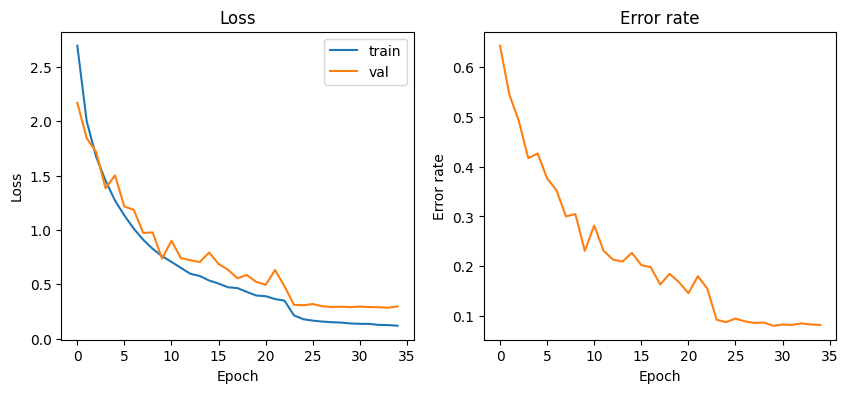

In [21]:
# plotting older runs
# To choose another experiment, replace this with e.g. run_to_plot = "run_002".
results_df = pd.read_csv(
    f"drive/MyDrive/gervigreing_lokaverk/experiments/experiment_summary_output{45}_blur.csv"
)
run_to_plot = results_df.iloc[0]["run_id"]

prediction_file = os.path.join(
    'drive/MyDrive/gervigreing_lokaverk/experiments/models', "run_6_trivial_allaug_rot90_test_predictions.npz"
)
if not os.path.exists(prediction_file):
    raise FileNotFoundError(
        f"No saved predictions for {run_to_plot}. "
        "Run the updated experiment loop first."
    )

with np.load(prediction_file, allow_pickle=False) as saved:
    y_true = saved["y_true"].copy()
    y_pred = saved["y_pred"].copy()
    class_names = saved["class_names"].tolist()

print(f"Selected experiment: {run_to_plot} (final-epoch test predictions)")
print(f"Test set accuracy: {100 * np.mean(y_true == y_pred):.2f}%")

history = pd.read_csv(
    os.path.join('drive/MyDrive/gervigreing_lokaverk/experiments', f"{run_to_plot}_history.csv")
)
plot_training(history.to_dict(orient="list"))

In [22]:
# plot a historic run
run_id = f'run_1_trivial'
results_df = pd.read_csv(
    f"drive/MyDrive/gervigreing_lokaverk/experiments/experiment_summary_output45_blur.csv"
)

results_df = results_df.sort_values(
    "best_val_accuracy",
    ascending=False
)

prediction_file = os.path.join(
    'drive/MyDrive/gervigreing_lokaverk/experiments/models', f"run_1_blur3-0.5_rot10_test_predictions_best11NOV.npz"
)
run_to_plot = results_df.iloc[0]["run_id"]

with np.load(prediction_file, allow_pickle=False) as saved:
    y_true = saved["y_true"].copy()
    y_pred = saved["y_pred"].copy()
    class_names = saved["class_names"].tolist()


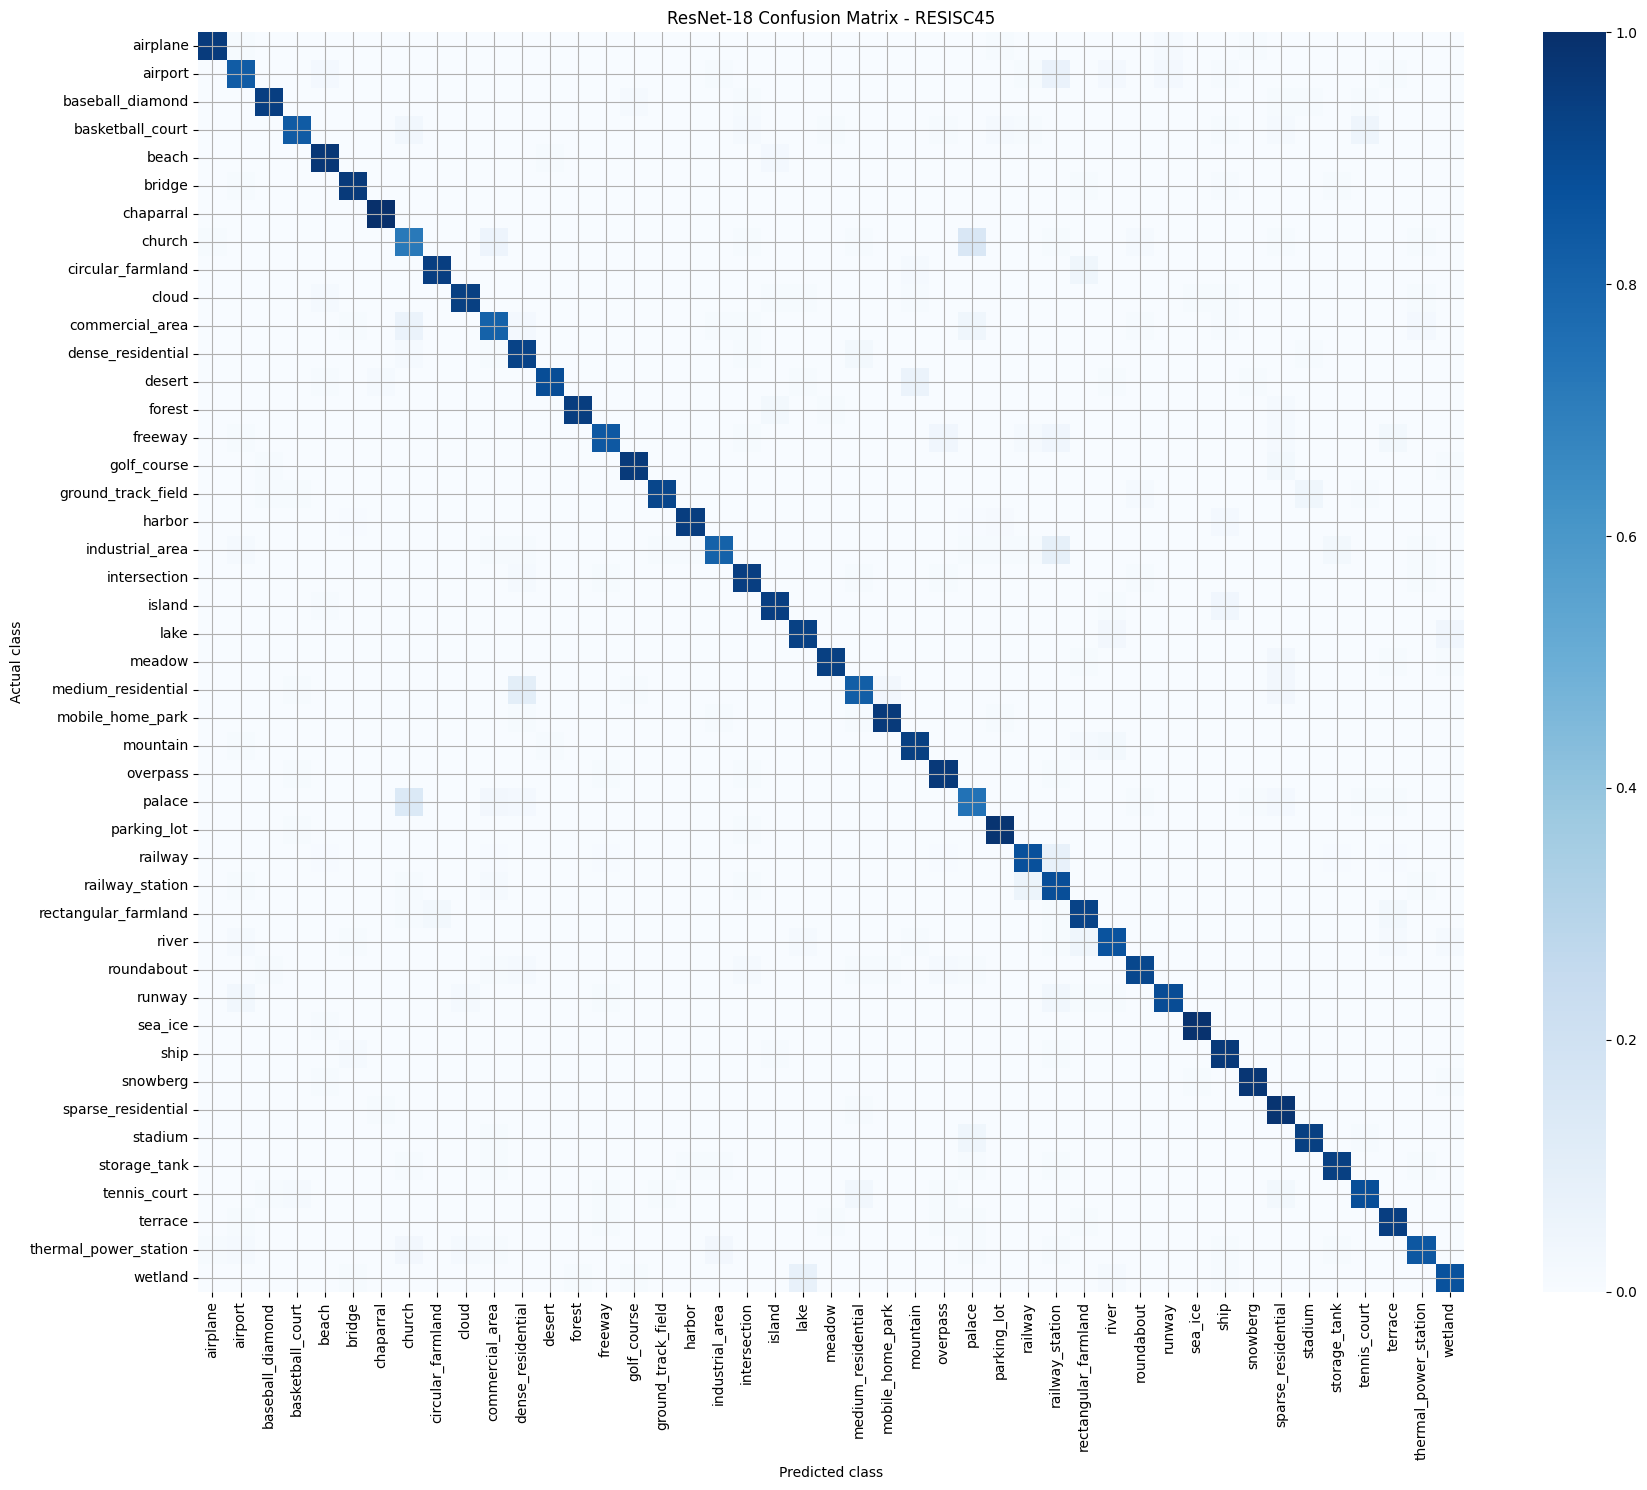


Classification Report:
                       precision    recall  f1-score   support

             airplane       0.98      0.96      0.97       112
              airport       0.84      0.83      0.84       101
     baseball_diamond       0.96      0.94      0.95       105
     basketball_court       0.94      0.83      0.88       114
                beach       0.92      0.97      0.94       102
               bridge       0.94      0.96      0.95       100
            chaparral       0.98      1.00      0.99       123
               church       0.71      0.72      0.72       111
    circular_farmland       0.98      0.94      0.96       126
                cloud       0.97      0.94      0.95       128
      commercial_area       0.81      0.81      0.81        98
    dense_residential       0.83      0.93      0.88       112
               desert       0.98      0.89      0.93       118
               forest       0.99      0.95      0.97       110
              freeway       0.

In [23]:
# confusion matrix
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

def plot_confusion_matrix(y_true, y_pred, class_names, device):

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_true, y_pred,
        labels=np.arange(len(class_names))
    )

    # Normalize by actual class
    cm_normalized = cm.astype(float) / np.maximum(
        cm.sum(axis=1, keepdims=True), 1
    )

    # Plot
    plt.figure(figsize=(18, 15))

    sns.heatmap(
        cm_normalized,
        annot=False,
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.title("ResNet-18 Confusion Matrix - RESISC45")
    plt.grid(visible=True)

    plt.xticks(rotation=90)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    print(f"Overall accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%")

class_names = full_dataset.classes

plot_confusion_matrix(
    y_true,
    y_pred,
    class_names,
    run_to_plot
)

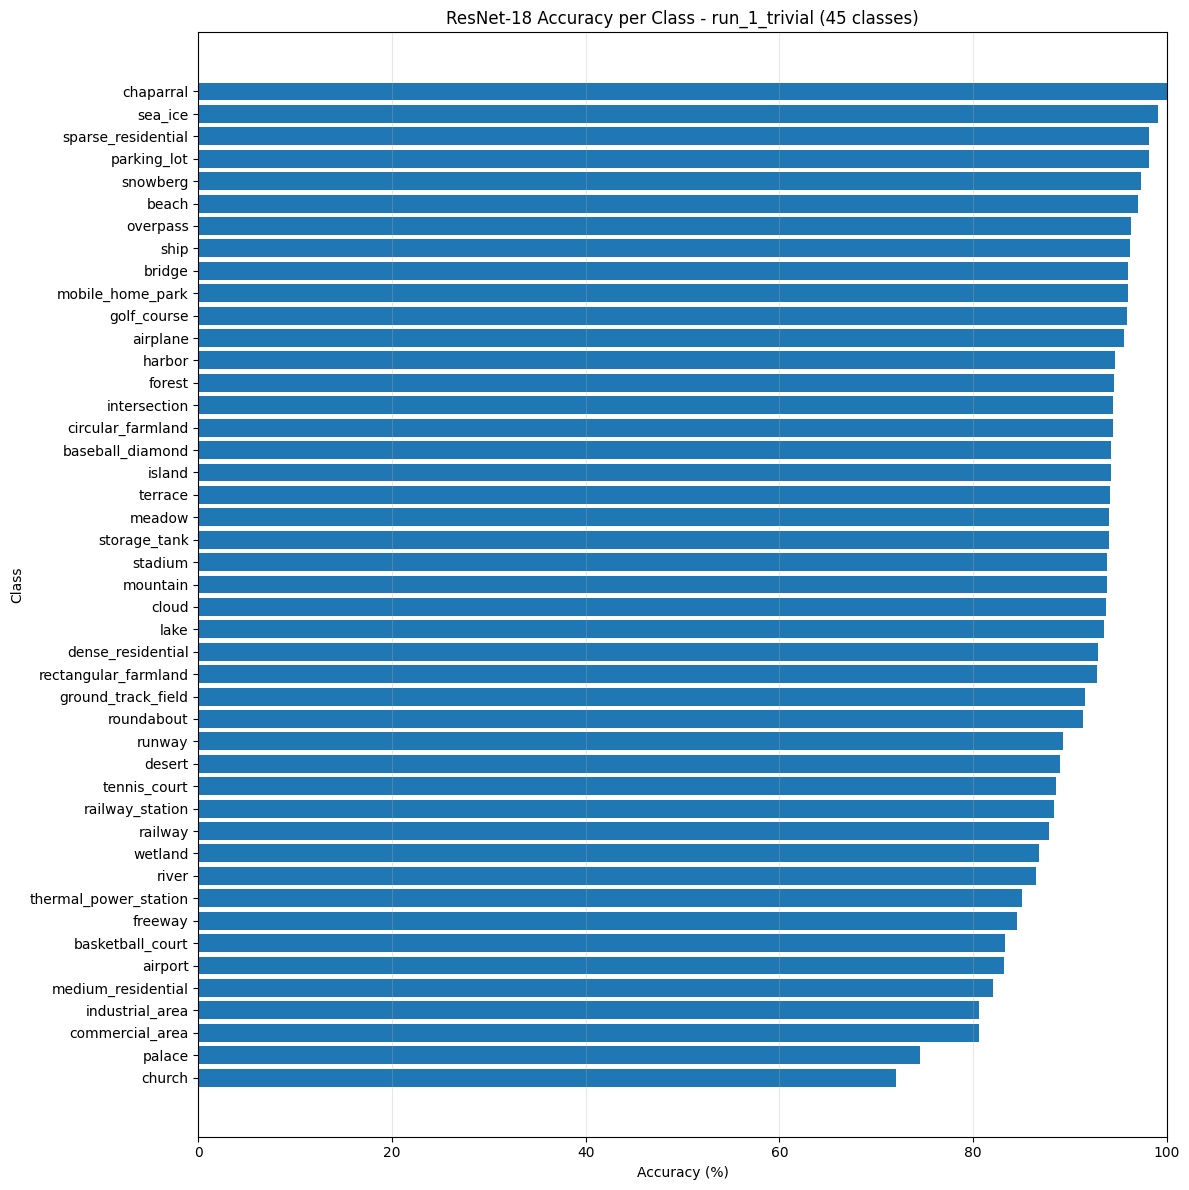

In [24]:
# accuracy for each class
def plot_class_accuracy(y_true, y_pred, class_names, device):

    # Confusion matrix
    cm = confusion_matrix(
        y_true, y_pred,
        labels=np.arange(len(class_names))
    )

    # Calculate accuracy for each class
    class_accuracy = 100 * cm.diagonal() / np.maximum(
        cm.sum(axis=1), 1
    )

    # Sort classes by accuracy
    sorted_idx = np.argsort(class_accuracy)

    sorted_names = np.array(class_names)[sorted_idx]
    sorted_accuracy = class_accuracy[sorted_idx]

    # Plot
    plt.figure(figsize=(12, 12))
    plt.barh(sorted_names, sorted_accuracy)
    plt.xlabel("Accuracy (%)")
    plt.ylabel("Class")
    plt.title(f"ResNet-18 Accuracy per Class - {run_id} ({len(class_names)} classes)")
    plt.xlim(0, 100)
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_class_accuracy(y_true, y_pred, class_names, run_to_plot)